# Figure 4 · perturbation prediction

PertOmni (masked, multi-dataset; 5 seeds) predicts a held-out gene by the
softmax(sim / 0.07)-weighted mean expression of the K training-side samples of the same cell line whose text
(`PertOmni_text`) or expression (`PertOmni_gene`) embedding is closest to the query's text embedding. Scores: Pearson
correlation of predicted and measured expression over all genes (`corr`) and over the top-20 DEGs (`corr_top20`),
mean over the held-out genes (PertOmni: and over the seeds). Dotted lines: the baselines (package README, section 5).

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")  # deprecation notices of the installed libraries
from pertomni import paths      # pip install -e . in the repository root
from pertomni.io import load_obj, save_obj

R = paths.DATA                  # published inputs and results (data/, or $PERTOMNI_DATA)
FIG = Path("figures")           # figures of this notebook, next to it
FIG.mkdir(exist_ok=True)
SEEDS = range(5)
# editable text in PDF / SVG (TrueType fonts, <text> elements)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})

In [2]:
D = R / "langpert" / "results" / "pertomni"
CLS = ["rpe1", "hepg2", "jurkat"]
METRICS = ["corr", "corr_top20"]
K_TABLE = 100  # PertOmni neighbours in the table
# baselines in the order and colours of the published line charts
BASELINES = {"PertOmni_text +refined LangPert": "cyan", "single pass LangPert": "red", "refined LangPert": "green",
             "non-ctrl mean": "gray", "GenePert": "blue", "STRING GNN": "olive"}

pertomni = pd.DataFrame([
    dict(method=f"PertOmni_{emb}", cl=cl, metric=metric, K=K, value=np.mean(values))
    for cl in CLS for emb in ["text", "gene"]
    for metric, per_K in load_obj(D / f"{cl}_{emb}_scores.pkl").items() if metric in METRICS
    for K, values in per_K.items() if values
])
baselines = pd.read_csv(D / "baselines.csv")

table = pd.concat([pertomni[pertomni["K"] == K_TABLE], baselines]).pivot_table(index="method", columns=["metric", "cl"], values="value")
table = table.reindex(list(BASELINES) + ["PertOmni_gene", "PertOmni_text"]).reindex(columns=pd.MultiIndex.from_product([METRICS, CLS]))
table.to_csv(FIG / "scores.csv")
print(f"PertOmni at K = {K_TABLE}")
table.round(4)

PertOmni at K = 100


corr                 corr_top20          \
                                   rpe1   hepg2  jurkat       rpe1   hepg2   
method                                                                       
PertOmni_text +refined LangPert  0.9579  0.9625  0.9688     0.9890  0.9867   
single pass LangPert             0.9555  0.9612  0.9673     0.9870  0.9847   
refined LangPert                 0.9564  0.9617  0.9680     0.9872  0.9850   
non-ctrl mean                    0.9569  0.9623  0.9706     0.9856  0.9847   
GenePert                         0.9582  0.9628  0.9694     0.9883  0.9863   
STRING GNN                       0.9598  0.9646  0.9712     0.9876  0.9867   
PertOmni_gene                    0.9580  0.9634  0.9703     0.9873  0.9854   
PertOmni_text                    0.9601  0.9647  0.9711     0.9894  0.9878   

                                         
                                 jurkat  
method                                   
PertOmni_text +refined LangPert  0.9910  
single pass LangPert             0.9901  
refined LangPert                 0.9903  
non-ctrl mean                    0.9908  
GenePert                         0.9910  
STRING GNN                       0.9913  
PertOmni_gene                    0.9900  
PertOmni_text                    0.9917

## Score vs number of neighbours K

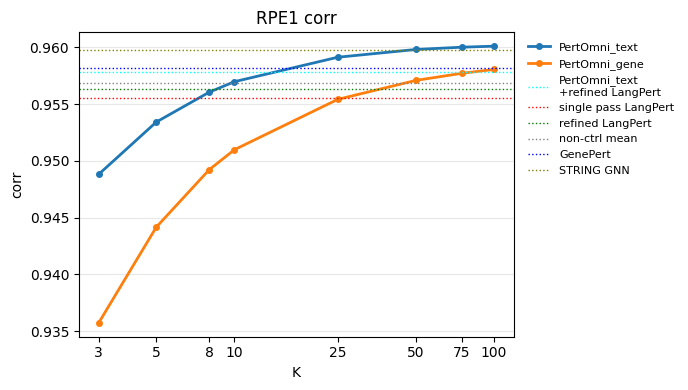

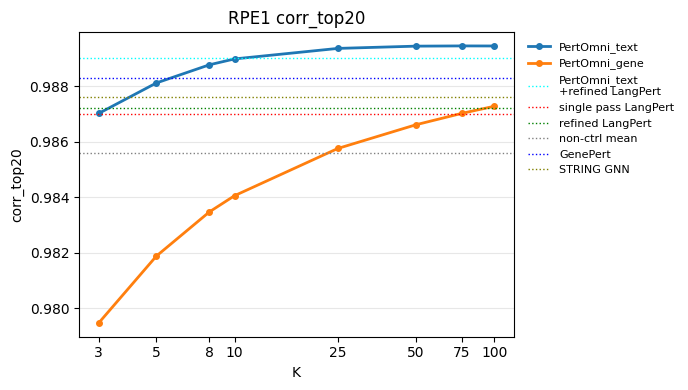

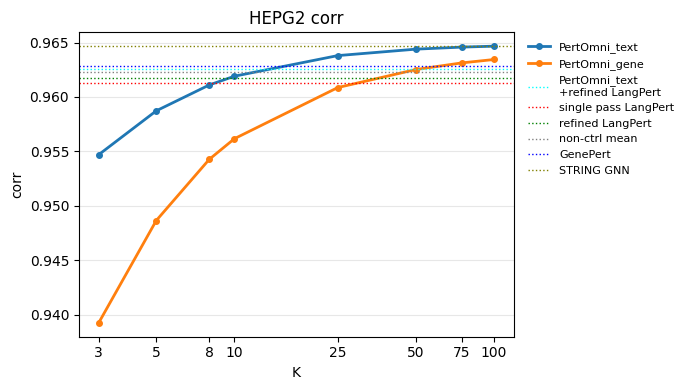

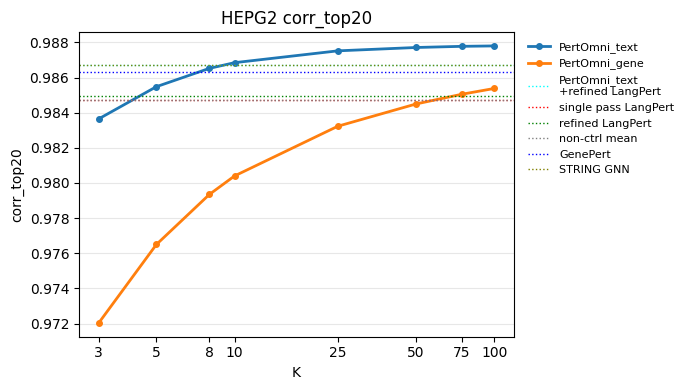

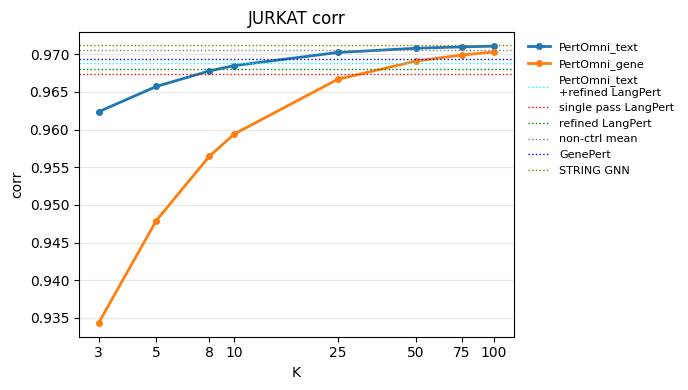

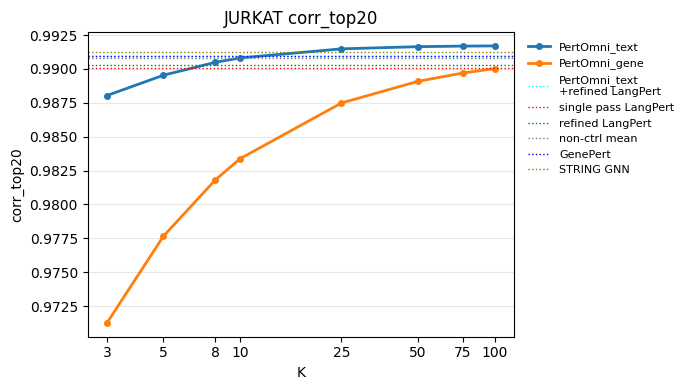

In [3]:
for cl in CLS:
    for metric in METRICS:
        fig, ax = plt.subplots(figsize=(7, 4))
        for emb in ["text", "gene"]:
            d = pertomni[(pertomni["cl"] == cl) & (pertomni["metric"] == metric) & (pertomni["method"] == f"PertOmni_{emb}")].sort_values("K")
            ax.plot(d["K"], d["value"], marker="o", lw=2, ms=4, label=f"PertOmni_{emb}")
        b = baselines[(baselines["cl"] == cl) & (baselines["metric"] == metric)].set_index("method")["value"]
        for method, color in BASELINES.items():
            ax.axhline(b[method], ls=":", lw=1, color=color, label=method.replace(" +", "\n+"))
        Ks = sorted(pertomni["K"].unique())
        ax.set_xscale("log")  # the published charts use a linear K axis, on which the labels of K = 3..10 overlap
        ax.set_xticks(Ks, [str(k) for k in Ks])
        ax.minorticks_off()
        ax.set_xlabel("K")
        ax.set_ylabel(metric)
        ax.set_title(f"{cl.upper()} {metric}")
        ax.grid(True, axis="y", alpha=0.3)
        ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
        fig.tight_layout()
        fig.savefig(FIG / f"linechart_{cl}_{metric}.pdf")
        plt.show()